# Isochrone analysis 

In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ezpadova
import pathlib

In [68]:
# ==============================================================================
# Loading one of the feh bin for further analysis
# ==============================================================================

path = "../../data/my_data/" 
file_name = "stars_bin8.csv" # Here I put the feh bin MUST agree with the chosen metallicity
stars_bin = pd.read_csv(path + file_name)

bin_edges_hard_feh = np.array([-1.6, -0.8, -0.5, -0.4, -0.3, -0.2, -0.1, 0.0, 0.1, 1.0])

bin_mean_feh = np.mean(stars_bin['feh'])
print("Mean feh in the bin: " + str(np.round(bin_mean_feh,3)))

bin_mean_mass = np.mean(stars_bin['mass_L_sl'])
print("Mean mass in the bin: " +str(np.round(bin_mean_mass,3)))

bin_mean_age = np.mean(stars_bin['age'])
print("Mean age in the bin: " +str(np.round(bin_mean_age,3)))


metallicity = bin_mean_feh #Metallicity for both, plot of observed and synthethic stars. 

Mean feh in the bin: 0.046
Mean mass in the bin: 1.224
Mean age in the bin: 6.109


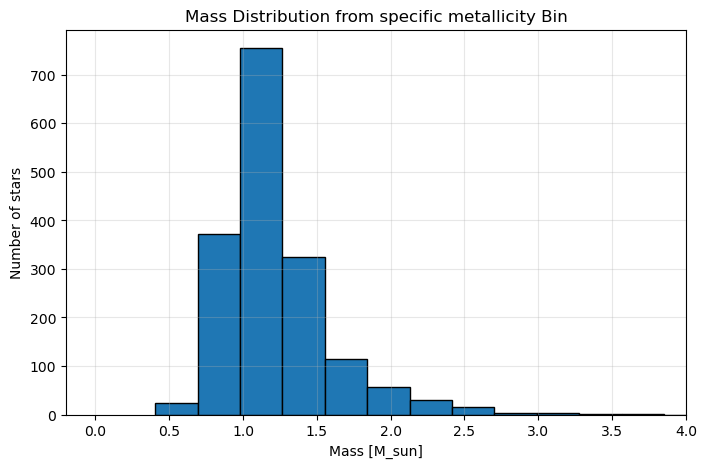

In [69]:
mass_bin = pd.to_numeric(
    stars_bin.loc[pd.Series(True, index=stars_bin['Teff'].index), 'mass_L_sl'],
    #stars_bin.loc[stars_bin['RelAge_Dnu'].astype(str).str.lower() == 'true', 'mass_L_sl'],
    errors='coerce'
).dropna()

plt.figure(figsize=(8, 5))
plt.hist(mass_bin, bins=30, edgecolor='black')
plt.xlim(-0.2,4)
plt.xlabel('Mass [M_sun]')
plt.ylabel('Number of stars')
plt.title('Mass Distribution from specific metallicity Bin')
plt.grid(True, alpha=0.3)
plt.show()

"[Fe/H] vs [m/H] I would not worry too much as the vast majority of secondary clump stars have [alpha/Fe]~0 so you can use [Fe/H] in the obs and [M/H] in PARSEC (btw PARSEC tracks I believe assume [alpha/Fe]=0, so effectively [M/H] is [Fe/H])" Miglio

"the alpha over iron can anyways create some problems when trying to match the isochrones"(Mucciarelli)

## PARSEC

In [ ]:

# Output directory
output_dir = pathlib.Path("parsec_isochrones")
output_dir.mkdir(exist_ok=True)

# Parameters
Mh = bin_mean_feh # Here I should put M/H but I put feh 
#ages = np.arange(1.65, 1.70, 0.01) * 1e9  # Years Range query
ages = np.array([1.0, 1.695, 2.5, 3.5, 5.0, 8.0, 12.0, 16.0]) * 1e9  # Years List query EDGES
ages = np.array([bin_mean_age]) * 1e9  # Years #Individual query MEAN

print(ages)

#sRC (logg=2.9) = 1e9
#2e9 -> 2.65 
#3e9 -> 2.52
#4e9 -> 2.49
#Age : 5e9 -> logg = 2.45 -> Mass = 1.25  
#RC (logg=2.3) = 7e9,8e9, 9e9

isochrones={}


for age in ages:

    print(f"Querying PARSEC: age = {age/1e9:.1f} Gyr")

    iso = ezpadova.get_isochrones(
        age_yr=(age, age, 0),
        MH=(metallicity, metallicity, 0),
        photsys_file="gaiaEDR3"
    )

    isochrones[age] = iso

    # Save
    filename = output_dir / f"isochrone_age_{age/1e9:.1f}Gyr.csv"
    iso.to_csv(filename, index=False)

    print(f"Saved {filename} | Points: {len(iso)}")

# Convert physical quantities
iso["Teff"] = 10**iso["logTe"]
iso["L"] = 10**iso["logL"]
Teff = 10**iso["logTe"]


[6.10948207e+09]
Querying PARSEC: age = 6.1 Gyr
Querying http://stev.oapd.inaf.it/cgi-bin/cmd...
Retrieving data...
Saved parsec_isochrones/isochrone_age_6.1Gyr.csv | Points: 304


ezpadova indeed has mass loss by default It uses Reimers prescription and efficiency 0.2. The Reimers prescription is an empirical formula used to estimate how much mass a star loses through stellar winds, particularly during the red giant branch (RGB).

6.11 Gyr: CHeB mass = 1.19 M☉


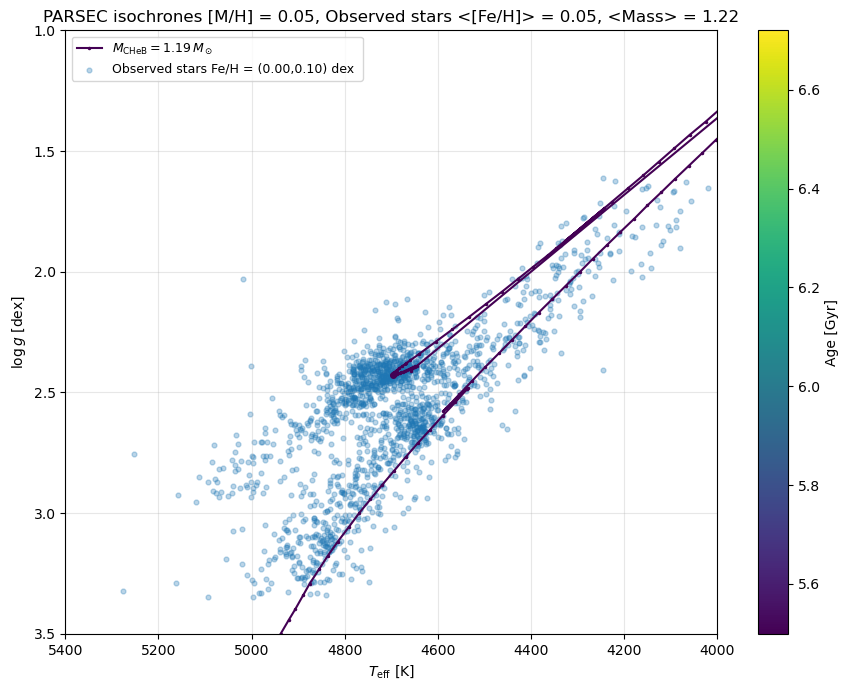

In [79]:
# ==============================================================================
# Plotting a pop in metallicity bin (all masses) and isochrones for different masses 
# ==============================================================================

fig, ax = plt.subplots(figsize=(9, 7))

cmap = plt.cm.viridis
norm = plt.Normalize(min(ages)/1e9, max(ages)/1e9)


for age, iso in isochrones.items():

    Teff = 10**iso["logTe"]

    idx = iso.iloc[150:200]["logg"].idxmax()
    ax.plot(Teff.loc[idx], iso.loc[idx, "logg"], marker="o", markersize=4, color=cmap(norm(age / 1e9)))

    iso_mass = iso.loc[idx, "Mini"]
    age_index = np.argmin(np.abs(ages - age))


    ax.plot(
        Teff,#[150:200],
        iso["logg"],#[150:200],
        marker=".",
        markersize=3,
        linestyle="-",
        color=cmap(norm(age/1e9)),
        label=rf"$M_{{\rm CHeB}}={iso_mass:.2f}\,M_\odot$"
    )

    
    idx = iso.iloc[150:200]["logg"].idxmax()
    #ax.plot(Teff.loc[idx], iso.loc[idx, "logg"], marker="o", markersize=4, color=cmap(norm(age / 1e9)))

    iso_mass = iso.loc[idx, "Mini"]
    age_index = np.argmin(np.abs(ages - age))

    iso_mass = iso.loc[idx, "Mini"]
    CHeB_label = iso.loc[idx, "label"]
    age_index = np.argmin(np.abs(ages - age))

    print(f"{age / 1e9:.2f} Gyr: CHeB mass = {iso_mass:.2f} M☉")

    
#plot the observed data

ax.scatter(stars_bin['Teff'], stars_bin['logg_scaling'], 
           s=12, alpha=0.3, label=rf'Observed stars Fe/H = ({0.0:.2f},{0.1:.2f}) dex ') 



# Colorbar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Age [Gyr]")

#plot the observed data

# Labels
ax.set_xlabel(r"$T_{\rm eff}\ [\mathrm{K}]$")
ax.set_ylabel(r"$\log g\ [\mathrm{dex}]$")
ax.set_title(rf"PARSEC isochrones [M/H] = {metallicity:.2f}, Observed stars <[Fe/H]> = {metallicity:.2f}, <Mass> = {bin_mean_mass:.2f}")

ax.set_xlim(5400, 4000)
ax.set_ylim(3.5,1.0)
plt.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

About bins: In general, younger clusters, higher masses require narrower bins 

Some stars further at teff larger than for the yougest star in a cluster of that metallicity 


! phase transition
From here I can conclude that the phase transition between RC and sRC is between 1.5 and 1.8 Gyrs when the maximum logg of the CHeB phase goes increases very very fast. The same phase transition can be indentified in mass, between 1.76 and 1.90 solar masses. So when binning in mass for solar metallicity one edge must fall in between this range (1.76 to 1.90 solar masses), for example taking the average of this range we can choose 1.85 solar masses.

"The transition in reality may be a little different as it depends on the size of the He core at the end of the MS, and this in the models can be changed by overshooting, rotational mixing et, but what is in PARSEC should provide a good guideline"(Miglio)

! bin errors
lets say we take the bin in mass [1.5, 1.4] a change in mass of 0.1, we can identify the respetively CHeB region in the diagram and check how much logg and teff change. For feh= 0.0 the logg changes between (2.50, 2.55) a difference of 0.05 dex and teff changes between (4772 ,4762) a difference of around 100 K

I cannot use it for RGB bump--> no phase transition
Could i use it for detecting where changes from RC to HB --> nice but useless for the purpose of separating CHeB from RGB

In [72]:
# ==============================================================================
# Dividing the pop with certain feh in bins of mass 
# ==============================================================================
#n_bins = 6, bin_edges = pd.qcut(mass, q=n_bins, retbins=True, duplicates='drop') # Same number of stars in each bin

bin_edges_hard_mass = np.array([0.5, 1.0, 1.1, 1.27, 1.4, 1.6, 1.84, 2.5]) # hard/flexible binning
n_bins = len(bin_edges_hard_mass) - 1


stars_with_feh_by_mass = {}
bin_center_mass = []

for i in range(n_bins):
    lower, upper = bin_edges_hard_mass[i], bin_edges_hard_mass[i + 1]

    print(f"Processing bin {i + 1}/{n_bins}: {lower:.2f} <= mass < {upper:.2f}, Stars in bin: {((stars_bin['mass_L_sl'] >= lower) & (stars_bin['mass_L_sl'] < upper)).sum()}")
    # Check if this is the very last subplot/bin in the loop
    in_bin = (stars_bin['mass_L_sl'] >= lower) & (stars_bin['mass_L_sl'] < upper)

    bin_center = np.round((lower + upper) / 2,2)
    bin_center_mass.append(bin_center)
    stars_with_feh_by_mass[bin_center_mass[i]] = stars_bin.loc[in_bin]


print("bin_center_mass: " + str(np.array(bin_center_mass)))

mass_edges_by_center = {
    center: (lower, upper)
    for center, lower, upper in zip(
        bin_center_mass,
        bin_edges_hard_mass[:-1],
        bin_edges_hard_mass[1:]
    )
}

print(mass_edges_by_center)

Processing bin 1/7: 0.50 <= mass < 1.00, Stars in bin: 448
Processing bin 2/7: 1.00 <= mass < 1.10, Stars in bin: 298
Processing bin 3/7: 1.10 <= mass < 1.27, Stars in bin: 403
Processing bin 4/7: 1.27 <= mass < 1.40, Stars in bin: 182
Processing bin 5/7: 1.40 <= mass < 1.60, Stars in bin: 165
Processing bin 6/7: 1.60 <= mass < 1.84, Stars in bin: 87
Processing bin 7/7: 1.84 <= mass < 2.50, Stars in bin: 93
bin_center_mass: [0.75 1.05 1.18 1.34 1.5  1.72 2.17]
{np.float64(0.75): (np.float64(0.5), np.float64(1.0)), np.float64(1.05): (np.float64(1.0), np.float64(1.1)), np.float64(1.18): (np.float64(1.1), np.float64(1.27)), np.float64(1.34): (np.float64(1.27), np.float64(1.4)), np.float64(1.5): (np.float64(1.4), np.float64(1.6)), np.float64(1.72): (np.float64(1.6), np.float64(1.84)), np.float64(2.17): (np.float64(1.84), np.float64(2.5))}


6.1 Gyr: average Mini in rows 150:200 = 1.19 M☉
<built-in method keys of dict object at 0x70014dfaa240>


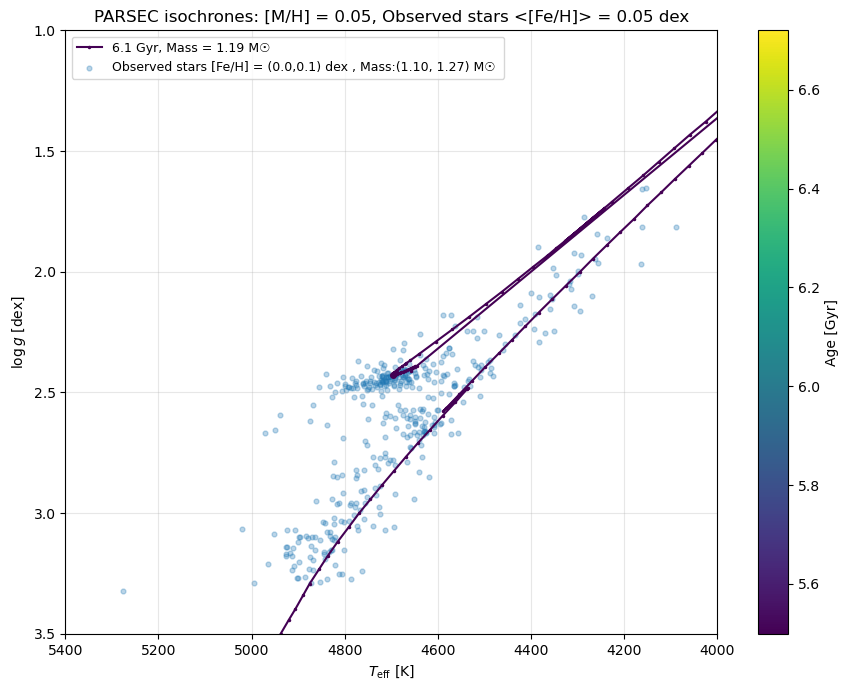

In [73]:
# ==============================================================================
# Plotting a metallicity bin and mass bin and isochrones for different masses 
# ==============================================================================

# Plot Kiel diagram
fig, ax = plt.subplots(figsize=(9, 7))

cmap = plt.cm.viridis
norm = plt.Normalize(min(ages)/1e9, max(ages)/1e9)


for age, iso in isochrones.items():

    Teff = 10**iso["logTe"]

    idx = iso.iloc[150:200]["logg"].idxmax()
    ax.plot(Teff.loc[idx], iso.loc[idx, "logg"], marker="o", markersize=4, color=cmap(norm(age / 1e9)))

    iso_mass = iso.loc[idx, "Mini"]
    age_index = np.argmin(np.abs(ages - age))


    ax.plot(
        Teff,#[80:300],
        iso["logg"],#[80:300],
        marker=".",
        markersize=3,
        linestyle="-",
        color=cmap(norm(age/1e9)),
        label=rf"{age / 1e9:.1f} Gyr, Mass = {iso_mass:.2f} M☉"
    )

    

    iso_mass = iso.iloc[80:300]["Mini"].mean()
    print(f"{age / 1e9:.1f} Gyr: average Mini in rows 150:200 = {iso_mass:.2f} M☉")

    
#plot the observed data
mass_center =  1.18 # Decide the mass to plot
print(stars_with_feh_by_mass.keys)
ax.scatter(stars_with_feh_by_mass[mass_center]['Teff'], stars_with_feh_by_mass[mass_center]['logg_scaling'], 
           s=12, alpha=0.3, label=rf'Observed stars [Fe/H] = ({0.0:.1f},{0.1:.1f}) dex , Mass:({mass_edges_by_center[mass_center][0]:.2f}, {mass_edges_by_center[mass_center][1]:.2f}) M☉ ') 



# Colorbar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Age [Gyr]")

#plot the observed data

# Labels
ax.set_xlabel(r"$T_{\rm eff}\ [\mathrm{K}]$")
ax.set_ylabel(r"$\log g\ [\mathrm{dex}]$")
ax.set_title(rf"PARSEC isochrones: [M/H] = {metallicity:.2f}, Observed stars <[Fe/H]> = {metallicity:.2f} dex")

ax.set_xlim(5400, 4000)
ax.set_ylim(3.5,1.0)
plt.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

The models fit good enough, maybe there are some that alpha elemetns corrupt. there is also many undertainities in boundaries, mixing lenght parameter, also error in effective temperature. This last could explain the offset in the position of the RGB bump, because a change in logg can create a change in logg. 

TO solve the problem of alpha enhancement I could use salaris convention  1993 

In [74]:
"""# Plot only one track signaling the RC region (Kiel diagram)
fig, ax = plt.subplots(figsize=(9, 7))

ax.plot(
    iso["Teff"],
    iso["logg"],
    marker=".",
    linestyle="-"
)


print(len(iso["Teff"]))
ax.plot(
    iso["Teff"][161:170],
    iso["logg"][161:170],
    marker=".",
    linestyle="-",
    color="orange"
)



ax.set_xlabel(r"$T_{\rm eff}\ [\mathrm{K}]$")
ax.set_ylabel(r"$\log g\ [\mathrm{dex}]$")
ax.set_xlim(5400, 4000)
ax.set_ylim(3.5,1.0)
ax.set_title(
    rf"PARSEC: Age = {age/1e9:.1f} Gyr, [M/H] = {metallicity:+.2f}"
)


ax.axhline(y=2.65, color="gray", linestyle="--", alpha=0.5, label="sRC (logg=2.9)")



ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()
"""

'# Plot only one track signaling the RC region (Kiel diagram)\nfig, ax = plt.subplots(figsize=(9, 7))\n\nax.plot(\n    iso["Teff"],\n    iso["logg"],\n    marker=".",\n    linestyle="-"\n)\n\n\nprint(len(iso["Teff"]))\nax.plot(\n    iso["Teff"][161:170],\n    iso["logg"][161:170],\n    marker=".",\n    linestyle="-",\n    color="orange"\n)\n\n\n\nax.set_xlabel(r"$T_{\rm eff}\\ [\\mathrm{K}]$")\nax.set_ylabel(r"$\\log g\\ [\\mathrm{dex}]$")\nax.set_xlim(5400, 4000)\nax.set_ylim(3.5,1.0)\nax.set_title(\n    rf"PARSEC: Age = {age/1e9:.1f} Gyr, [M/H] = {metallicity:+.2f}"\n)\n\n\nax.axhline(y=2.65, color="gray", linestyle="--", alpha=0.5, label="sRC (logg=2.9)")\n\n\n\nax.grid(alpha=0.3)\nfig.tight_layout()\nplt.show()\n'

### Studying the RGB location

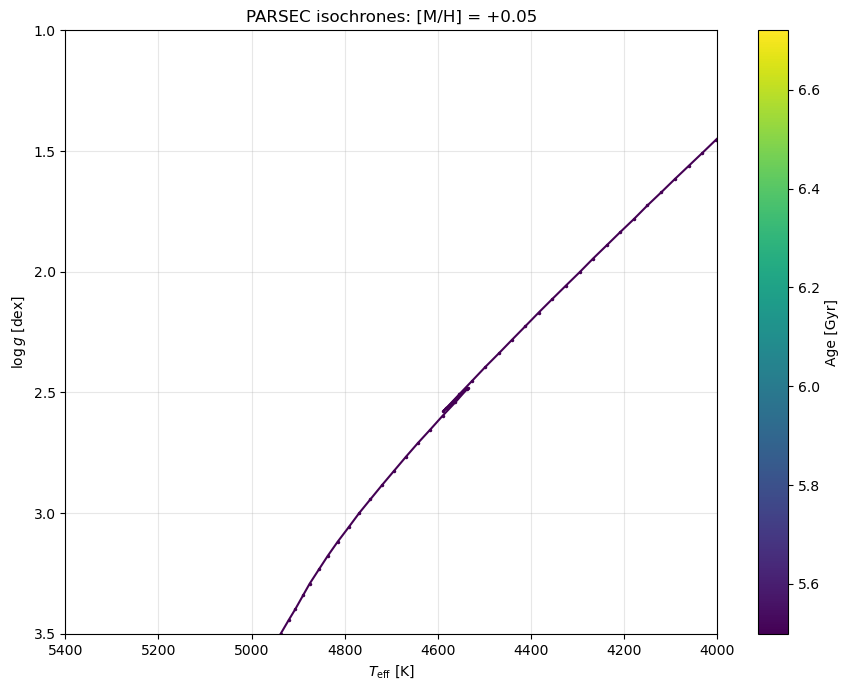

In [75]:
# Plot Kiel diagram
fig, ax = plt.subplots(figsize=(9, 7))

cmap = plt.cm.viridis
norm = plt.Normalize(min(ages)/1e9, max(ages)/1e9)

for age, iso in isochrones.items():

    Teff = 10**iso["logTe"]
    
    ax.plot(
        Teff[10:120],
        iso["logg"][10:120],
        marker=".",
        markersize=3,
        linestyle="-",
        color=cmap(norm(age/1e9)),
        label=f"{age/1e9:.1f} Gyr"
    )

"""    
    idx = iso.iloc[10:100]["logg"].idxmax()
    ax.plot(Teff.loc[idx], iso.loc[idx, "logg"], marker="o", markersize=4, color=cmap(norm(age / 1e9)))

    CHeB_mass = iso.loc[idx, "Mini"]
    age_index = np.argmin(np.abs(ages - age))

    CHeB_mass = iso.loc[idx, "Mini"]
    CHeB_label = iso.loc[idx, "label"]
    age_index = np.argmin(np.abs(ages - age))"""

"""    ax.text(
        0.03,
        0.97 - age_index * 0.055,
        (
            rf"{age / 1e9:.1f} Gyr: $M_{{\rm CHeB}}={CHeB_mass:.2f}\,M_\odot$"
            #rf"  (label={CHeB_label}, "
            #rf"Teff={Teff.loc[idx]:.0f} K, logg={iso.loc[idx, 'logg']:.2f})"
        ),
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=9,
        color=cmap(norm(age / 1e9))
    )"""

# Colorbar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Age [Gyr]")

# Labels
ax.set_xlabel(r"$T_{\rm eff}\ [\mathrm{K}]$")
ax.set_ylabel(r"$\log g\ [\mathrm{dex}]$")
ax.set_title(rf"PARSEC isochrones: [M/H] = {metallicity:+.2f}")

ax.set_xlim(5400, 4000)
ax.set_ylim(3.5,1.0)

ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [76]:
print(iso.columns.tolist())

# Original PARSEC header/comments
print(iso.attrs.get("comment"))  #I have to add the reference to the PARSEC paper in the final version of the notebook/thesis

['Zini', 'MH', 'logAge', 'Mini', 'int_IMF', 'Mass', 'logL', 'logTe', 'logg', 'label', 'McoreTP', 'C_O', 'period0', 'period1', 'period2', 'period3', 'period4', 'pmode', 'Mloss', 'tau1m', 'X', 'Y', 'Xc', 'Xn', 'Xo', 'Cexcess', 'Z', 'mbolmag', 'Gmag', 'G_BPmag', 'G_RPmag', 'Teff', 'L']
File generated by CMD 3.9 (http://stev.oapd.inaf.it/cmd) on Tue Nov 10 15:37:23 UTC 2026
isochrones based on PARSEC release v1.2S +  COLIBRI S_37 + S_35 + PR16
Basic references: Bressan et al. (2012), MNRAS, 427, 127 + Chen et al. (2014, 2015), MNRAS, 444, 2525 + MNRAS, 452, 1068 + Tang et al. (2014), MNRAS, 445, 4287 + Marigo et al. (2017), ApJ, 835, 77 + Pastorelli al. (2019), MNRAS, 485, 5666 + Pastorelli al. (2020), MNRAS, in press
Thermal pulse cycles included
On RGB, assumed Reimers mass loss with efficiency eta=0.2
LPV periods and growth rates added cf. Trabucchi et al. (2019)
but fundamental-mode LPV periods are from Trabucchi et al. (2021)
Photometric system: Gaia EDR3 (all Vegamags, Gaia passbands

=== Mass Bin Statistics ===
$M < 1.00\ M_\odot$ (Low-mass RC):  452 stars (26.6%)
$1.00 \leq M < 1.25\ M_\odot$ (Standard RC):  661 stars (38.9%)
$1.25 \leq M < 1.50\ M_\odot$ (Intermediate RC):  325 stars (19.1%)
$1.50 \leq M < 1.83\ M_\odot$ (Pre-transition):  146 stars (8.6%)
$M \geq 1.83\ M_\odot$ (Secondary RC):  115 stars (6.8%)


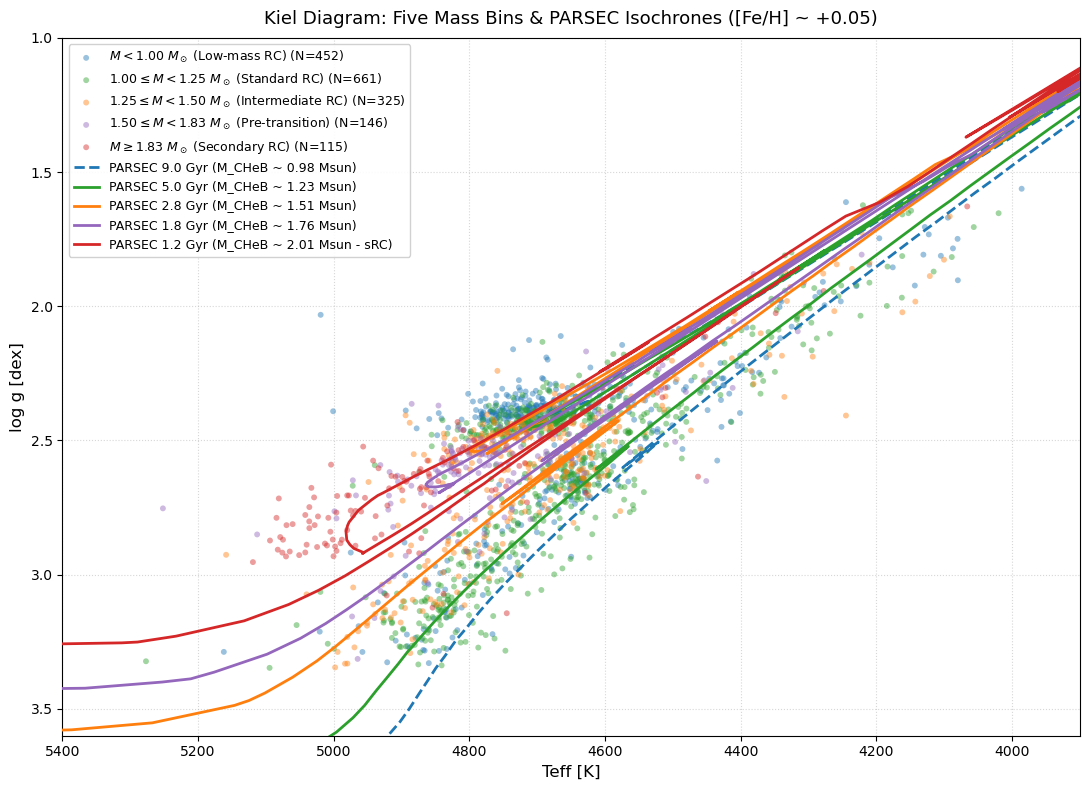

In [82]:
# ==============================================================================
# Five-Bin Mass Classification & Kiel Diagram with PARSEC Isochrones
# ==============================================================================

# 1. Define physical mass bin edges and labels
mass_edges = [0.0, 1.00, 1.25, 1.50, 1.83, np.inf]
mass_bin_labels = [
    r"$M < 1.00\ M_\odot$ (Low-mass RC)",
    r"$1.00 \leq M < 1.25\ M_\odot$ (Standard RC)",
    r"$1.25 \leq M < 1.50\ M_\odot$ (Intermediate RC)",
    r"$1.50 \leq M < 1.83\ M_\odot$ (Pre-transition)",
    r"$M \geq 1.83\ M_\odot$ (Secondary RC)"
]

bin_colors = ["#1f77b4", "#2ca02c", "#ff7f0e", "#9467bd", "#d62728"]

# 2. Filter valid observed stars with measured mass, Teff, and logg
valid_stars = stars_bin.dropna(subset=["mass_L_sl", "Teff", "logg_scaling"]).copy()
valid_stars["mass_L_sl"] = pd.to_numeric(valid_stars["mass_L_sl"], errors="coerce")
valid_stars = valid_stars.dropna(subset=["mass_L_sl"])

valid_stars["mass_bin"] = pd.cut(
    valid_stars["mass_L_sl"],
    bins=mass_edges,
    labels=mass_bin_labels,
    right=False
)

# Print star statistics per bin
print("=== Mass Bin Statistics ===")
for label in mass_bin_labels:
    cnt = (valid_stars["mass_bin"] == label).sum()
    pct = 100 * cnt / len(valid_stars)
    print(f"{label}: {cnt:4d} stars ({pct:.1f}%)")

# 3. Representative ages corresponding to CHeB masses in each bin
rep_ages_gyr = [9.0, 5.0, 2.8, 1.8, 1.2]
rep_iso_styles = [
    {"color": "#1f77b4", "ls": "--", "label": "PARSEC 9.0 Gyr (M_CHeB ~ 0.98 Msun)"},
    {"color": "#2ca02c", "ls": "-",  "label": "PARSEC 5.0 Gyr (M_CHeB ~ 1.23 Msun)"},
    {"color": "#ff7f0e", "ls": "-",  "label": "PARSEC 2.8 Gyr (M_CHeB ~ 1.51 Msun)"},
    {"color": "#9467bd", "ls": "-",  "label": "PARSEC 1.8 Gyr (M_CHeB ~ 1.76 Msun)"},
    {"color": "#d62728", "ls": "-",  "label": "PARSEC 1.2 Gyr (M_CHeB ~ 2.01 Msun - sRC)"}
]

# 4. Create the Kiel diagram plot
fig, ax = plt.subplots(figsize=(11, 8))

# Scatter plot of observed stars color-coded by mass bin
for label, color in zip(mass_bin_labels, bin_colors):
    subset = valid_stars[valid_stars["mass_bin"] == label]
    ax.scatter(
        subset["Teff"],
        subset["logg_scaling"],
        c=color,
        s=18,
        alpha=0.45,
        edgecolor="none",
        label=f"{label} (N={len(subset)})",
        zorder=2
    )

# Overplot representative PARSEC isochrones from local directory or isochrones dict
iso_dir = pathlib.Path("parsec_isochrones")
for age_gyr, style in zip(rep_ages_gyr, rep_iso_styles):
    iso_file = iso_dir / f"isochrone_age_{age_gyr:.1f}Gyr.csv"
    iso_df = None
    if iso_file.exists():
        iso_df = pd.read_csv(iso_file)
    elif "isochrones" in locals():
        for a_key, a_val in isochrones.items():
            if np.isclose(a_key / 1e9, age_gyr, atol=0.05):
                iso_df = a_val
                break
    if iso_df is not None:
        teff_iso = 10**iso_df["logTe"]
        logg_iso = iso_df["logg"]
        ax.plot(
            teff_iso,
            logg_iso,
            color=style["color"],
            linestyle=style["ls"],
            linewidth=2.0,
            label=style["label"],
            zorder=3
        )

# Axis configuration for Kiel diagram
ax.set_xlabel("Teff [K]", fontsize=12)
ax.set_ylabel("log g [dex]", fontsize=12)
ax.set_title(
    f"Kiel Diagram: Five Mass Bins & PARSEC Isochrones ([Fe/H] ~ {bin_mean_feh:+.2f})",
    fontsize=13,
    pad=10
)

ax.set_xlim(5400, 3900)
ax.set_ylim(3.6, 1.0)
ax.grid(True, linestyle=":", alpha=0.5, zorder=1)

ax.legend(
    loc="upper left",
    fontsize=9,
    framealpha=0.9,
    ncol=1
)

fig.tight_layout()
plt.show()


=== 4-Bin Mass Statistics ===
$0.5 < M < 1.05\ M_\odot$:  600 stars (35.3%)
$1.05 < M < 1.30\ M_\odot$:  601 stars (35.4%)
$1.30 < M < 1.83\ M_\odot$:  379 stars (22.3%)
$1.83 < M < 2.5 M_\odot$:   96 stars (5.7%)


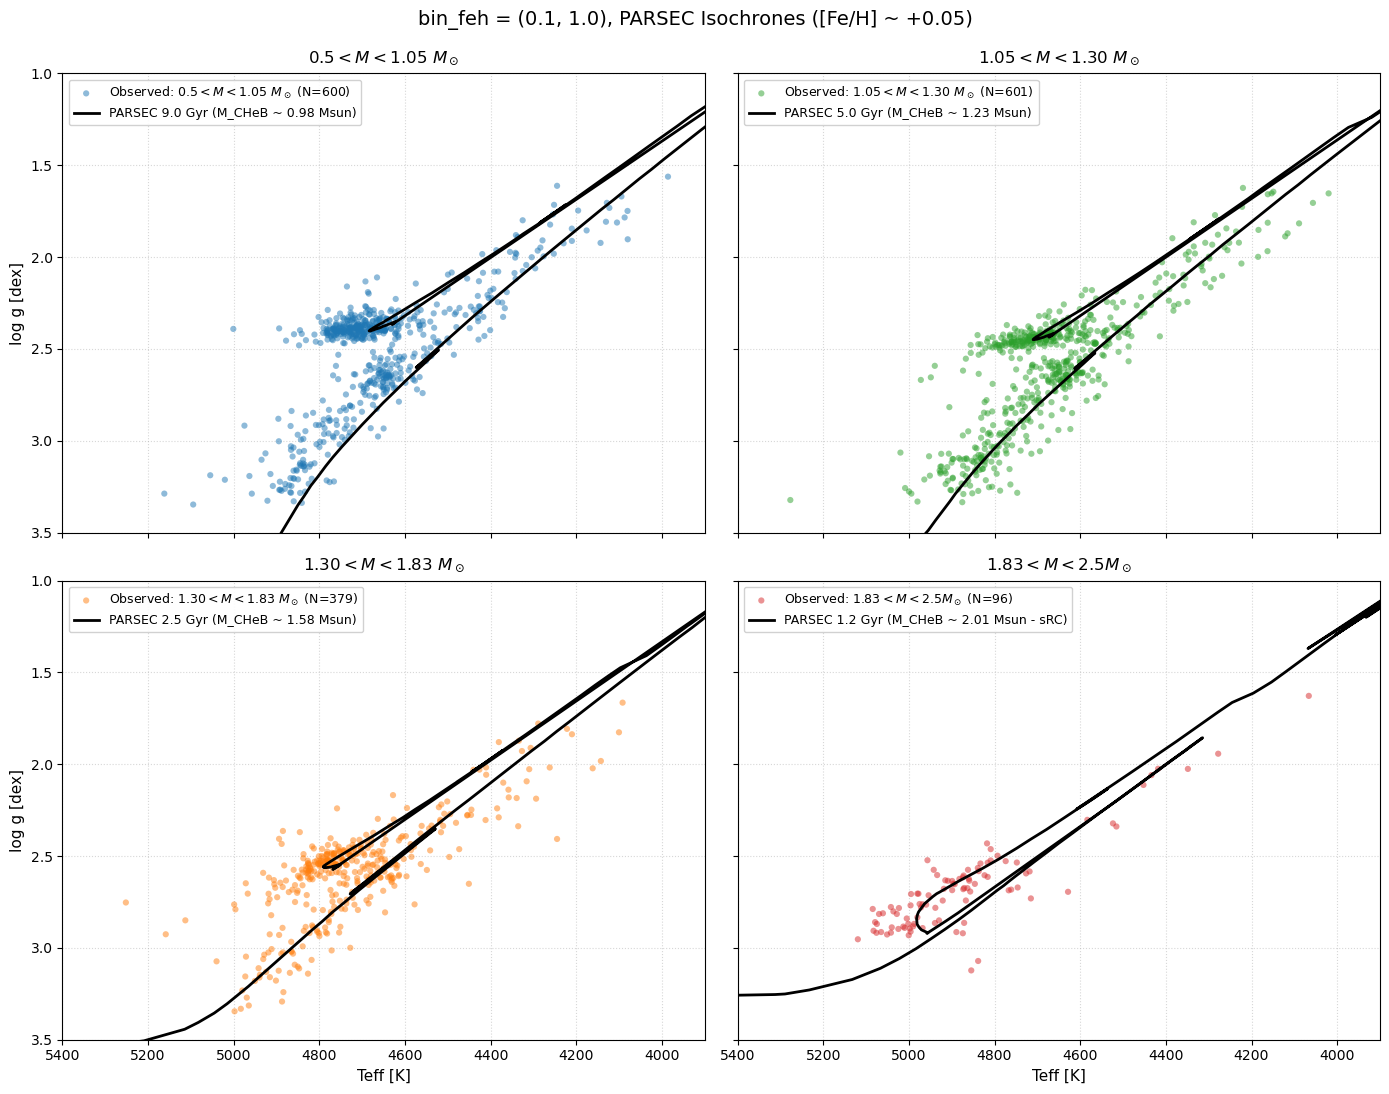

In [ ]:
# ==============================================================================
# Four-Bin Mass Classification & 2x2 Kiel Diagram with PARSEC Isochrones
# ==============================================================================

# 1. Define 4 physical mass bins and labels
# - [0.0, 1.00): Low-mass classical RC, radiative MS core, long lifetime
# - [1.00, 1.30): Core sample peak, onset of MS convective core, standard He-flash RC
# - [1.30, 1.83): Intermediate/pre-transition regime, fully developed convective core
# - [1.83, inf): Secondary Red Clump (sRC), non-degenerate He-core ignition

mass_edges_4 = [0.5, 1.05, 1.30, 1.83, 2.5]

mass_bin_labels_4 = [
    r"$0.5 < M < 1.05\ M_\odot$",
    r"$1.05 < M < 1.30\ M_\odot$",
    r"$1.30 < M < 1.83\ M_\odot$",
    r"$1.83 < M < 2.5 M_\odot$"
]

bin_colors_4 = ["#1f77b4", "#2ca02c", "#ff7f0e", "#d62728"]

# Representative ages matching the CHeB clump mass of each bin
rep_ages_4 = [9.0, 5.0, 2.5, 1.2]
rep_iso_labels_4 = [
    "PARSEC 9.0 Gyr (M_CHeB ~ 0.98 Msun)",
    "PARSEC 5.0 Gyr (M_CHeB ~ 1.23 Msun)",
    "PARSEC 2.5 Gyr (M_CHeB ~ 1.58 Msun)",
    "PARSEC 1.2 Gyr (M_CHeB ~ 2.01 Msun)"
]

# 2. Filter valid observed stars with measured mass, Teff, and logg
plot_data = stars_bin.dropna(subset=["mass_L_sl", "Teff", "logg_scaling"]).copy()

plot_data["mass_bin"] = pd.cut(
    plot_data["mass_L_sl"],
    bins=mass_edges_4,
    labels=mass_bin_labels_4,
    right=False
)

# Print star statistics per bin
print("=== 4-Bin Mass Statistics ===")
for label in mass_bin_labels_4:
    cnt = (plot_data["mass_bin"] == label).sum()
    pct = 100 * cnt / len(plot_data)
    print(f"{label}: {cnt:4d} stars ({pct:.1f}%)")

# 3. Create 2x2 subplot layout
fig, axes = plt.subplots(2, 2, figsize=(14, 11), sharex=True, sharey=True)
axes_flat = axes.flatten()

iso_dir = pathlib.Path("parsec_isochrones")

for i, (ax, label, color, age_gyr, iso_lbl) in enumerate(
    zip(axes_flat, mass_bin_labels_4, bin_colors_4, rep_ages_4, rep_iso_labels_4)
):
    subset = plot_data[plot_data["mass_bin"] == label]

    # Plot observed stars of this specific bin
    ax.scatter(
        subset["Teff"],
        subset["logg_scaling"],
        c=color,
        s=20,
        alpha=0.5,
        edgecolor="none",
        label=f"Observed: {label} (N={len(subset)})",
        zorder=2
    )

    # Load and overplot corresponding single isochrone
    iso_file = iso_dir / f"isochrone_age_{age_gyr:.1f}Gyr.csv"
    iso_df = None

    if iso_file.exists():
        iso_df = pd.read_csv(iso_file)
    elif "isochrones" in locals():
        for a_key, a_val in isochrones.items():
            if np.isclose(a_key / 1e9, age_gyr, atol=0.05):
                iso_df = a_val
                break

    if iso_df is not None:
        teff_iso = 10**iso_df["logTe"]
        logg_iso = iso_df["logg"]
        ax.plot(
            teff_iso,
            logg_iso,
            color="black",
            linestyle="-",
            linewidth=2.0,
            label=iso_lbl,
            zorder=3
        )

    # Subplot styling
    ax.set_title(label, fontsize=12, fontweight="bold", pad=8)
    ax.grid(True, linestyle=":", alpha=0.5, zorder=1)
    ax.legend(loc="upper left", fontsize=9, framealpha=0.9)

    # Axis labels for outer edges
    if i in [2, 3]:
        ax.set_xlabel("Teff [K]", fontsize=11)
    if i in [0, 2]:
        ax.set_ylabel("log g [dex]", fontsize=11)

# Invert axes for Kiel diagram standard
axes_flat[0].set_xlim(5400, 3900)
axes_flat[0].set_ylim(3.5, 1.0)

fig.suptitle(
    f"bin_feh = (0.1, 1.0), PARSEC Isochrones ([Fe/H] ~ {bin_mean_feh:+.2f})",
    fontsize=14,
    y=0.99
)

fig.tight_layout()
plt.show()